# Tutorial

Originally [from the Pyro intro](https://pyro.ai/examples/intro_long.html)

In [1]:
%reset -s -f


In [2]:
import logging
import os

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statistics
import scipy.stats as stats

import torch
import torch.nn as nn

import pyro
import pyro.distributions as dist
import pyro.distributions.transforms as transforms
import pyro.distributions.constraints as constraints
from pyro.nn import PyroModule, PyroSample

from pyro.infer import MCMC, NUTS, RandomWalkKernel, HMC
from pyro.infer import Predictive

# Construct data

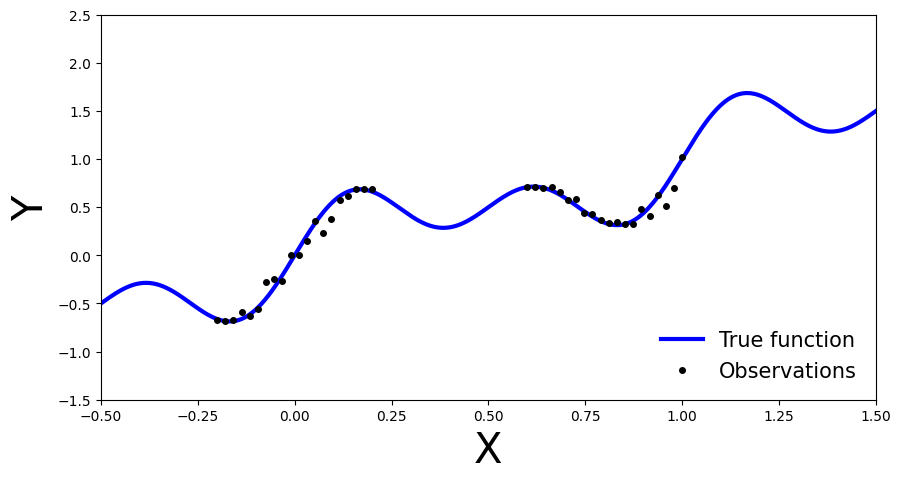

In [3]:


# Set random seed for reproducibility
np.random.seed(42)

nobs = 40

# Generate data
x_obs = np.hstack([np.linspace(-0.2, 0.2, nobs // 2), np.linspace(0.6, 1, nobs // 2)])
noise = 0.02 * np.random.randn(x_obs.shape[0])
y_obs = x_obs + 0.3 * np.sin(2 * np.pi * (x_obs + noise)) + 0.3 * np.sin(4 * np.pi * (x_obs + noise)) + noise

x_true = np.linspace(-0.5, 1.5, 1000)
y_true = x_true + 0.3 * np.sin(2 * np.pi * x_true) + 0.3 * np.sin(4 * np.pi * x_true)

# Convert data to PyTorch tensors
x_train = torch.from_numpy(x_obs).float()
y_train = torch.from_numpy(y_obs).float()

# Set plot limits and labels
xlims = [-0.5, 1.5]
ylims = [-1.5, 2.5]

x_test = torch.linspace(xlims[0], xlims[1], 3000)

# Create plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_true, y_true, 'b-', linewidth=3, label="True function")
ax.plot(x_obs, y_obs, 'ko', markersize=4, label="Observations")
ax.set_xlim(xlims)
ax.set_ylim(ylims)
ax.set_xlabel("X", fontsize=30)
ax.set_ylabel("Y", fontsize=30)
ax.legend(loc=4, fontsize=15, frameon=False)

plt.show()


x_train2 = x_train.reshape((*x_train.shape, 1))
y_train2 = y_train.reshape((*y_train.shape, 1))
x_test2 = x_test.reshape((*x_test.shape, 1))

In [4]:
def do_svi(svi, *args, check_interval=1000, max_nonimproved = 3, **kwargs):
    losses = []
    current_loss = 0
    nonimproved = 0
    while nonimproved < max_nonimproved:
        loss = svi.step(*args, **kwargs)
        losses.append(loss)
        if len(losses) >= 2 * check_interval and len(losses) % check_interval == 0:
            current_loss = statistics.mean(losses[-check_interval:])
            reg = stats.linregress(range(2*check_interval), losses[-2*check_interval:], alternative = "less")
            if reg.pvalue > 0.1:
                nonimproved += 1
            else:
                nonimproved = 0
            logging.info("Step {} Average Elbo loss: {:.1f} (slope = {:.3f} loss/k-iter, p-value = {:.3f}) {}".format(len(losses), current_loss, 1000*reg.slope, reg.pvalue, '*'*nonimproved))
    return losses

In [5]:
def plot_predictions(preds):
    y_pred = preds['obs'].T.detach().numpy().mean(axis=1)
    y_std = preds['obs'].T.detach().numpy().std(axis=1)

    fig, ax = plt.subplots(figsize=(10, 5))
    xlims = [-0.5, 1.5]
    ylims = [-1.5, 2.5]
    plt.xlim(xlims)
    plt.ylim(ylims)
    plt.xlabel("X", fontsize=30)
    plt.ylabel("Y", fontsize=30)

    ax.plot(x_true, y_true, 'b-', linewidth=3, label="true function")
    ax.plot(x_obs, y_obs, 'ko', markersize=4, label="observations")
    ax.plot(x_obs, y_obs, 'ko', markersize=3)
    ax.plot(x_test, y_pred, '-', linewidth=3, color="#408765", label="predictive mean")
    ax.fill_between(x_test, y_pred - 2 * y_std, y_pred + 2 * y_std, alpha=0.6, color='#86cfac', zorder=5)

    plt.legend(loc=4, fontsize=15, frameon=False)

def plot_predictions2(preds):
    y_pred = preds['mu'].squeeze().T.detach().numpy().mean(axis=1)
    y_std = preds['mu'].squeeze().T.detach().numpy().std(axis=1)

    fig, ax = plt.subplots(figsize=(10, 5))
    xlims = [-0.5, 1.5]
    ylims = [-1.5, 2.5]
    plt.xlim(xlims)
    plt.ylim(ylims)
    plt.xlabel("X", fontsize=30)
    plt.ylabel("Y", fontsize=30)

    ax.plot(x_true, y_true, 'b-', linewidth=3, label="true function")
    ax.plot(x_obs, y_obs, 'ko', markersize=4, label="observations")
    ax.plot(x_obs, y_obs, 'ko', markersize=3)
    ax.plot(x_test, y_pred, '-', linewidth=3, color="#408765", label="predictive mean")
    ax.fill_between(x_test, y_pred - 2 * y_std, y_pred + 2 * y_std, alpha=0.6, color='#86cfac', zorder=5)

    for inst in range(preds['mu'].shape[0]):
        y_inst = preds['mu'].squeeze()[inst,:]
        ax.plot(x_test, y_inst, '-', linewidth=0.5, alpha=0.5, color="red")

    plt.legend(loc=4, fontsize=15, frameon=False)

## With Custom Conditional Last Layer Guide

In [6]:
from mmbo.nn import TIBNN2, TIBNN2Guide

logging.basicConfig(format='%(message)s', level=logging.INFO)

pyro.clear_param_store()

model = TIBNN2.from_data(x_train2, y_train2, width=500, depth=2)
guide = TIBNN2Guide(model, x_train2, y_train2)

adam = pyro.optim.Adam({"lr": 0.001})
elbo = pyro.infer.Trace_ELBO(num_particles = 1)
svi = pyro.infer.SVI(model, guide, adam, elbo)

losses = do_svi(svi, x_train2, y_train2, check_interval = 500)

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")
/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")
Step 1000 Average Elbo loss: 3869.9 (slope = -46034.428 loss/k-iter, p-value = 0.000) 
Step 1500 Average Elbo loss: 3577.1 (slope = -595.472 loss/k-iter, p-value = 0.000) 
Step 2000 Average Elbo loss: 3464.2 (slope = -228.000 loss/k-iter, p-value = 0.000) 
Step 2500 Average Elbo loss: 3421.6 (slope = -81.670 loss/k-iter, p-value = 0.000) 
Step 3000 Average Elbo loss: 3395.8 (slope = -43.406 loss/k-iter, p-value = 0.000) 
Step 3500 Average Elbo loss: 3389.4 (slope = -15.637 loss/k-iter, p-value = 0.049) 
Step 4000 Average Elbo loss: 3386.9 (slope = -7.526 loss/k-iter, p-value = 0.202) *
Step 4500 Average Elbo loss: 3383.0 (slop

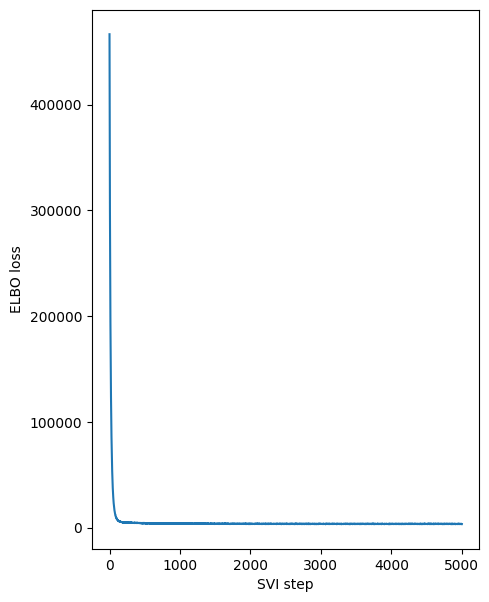

In [7]:
plt.figure(figsize=(5, 7))
plt.plot(losses)
plt.xlabel("SVI step")
plt.ylabel("ELBO loss");

In [8]:
svi_predictive = Predictive(model, guide=guide, num_samples=100)
svi_samples = svi_predictive(x_test2)

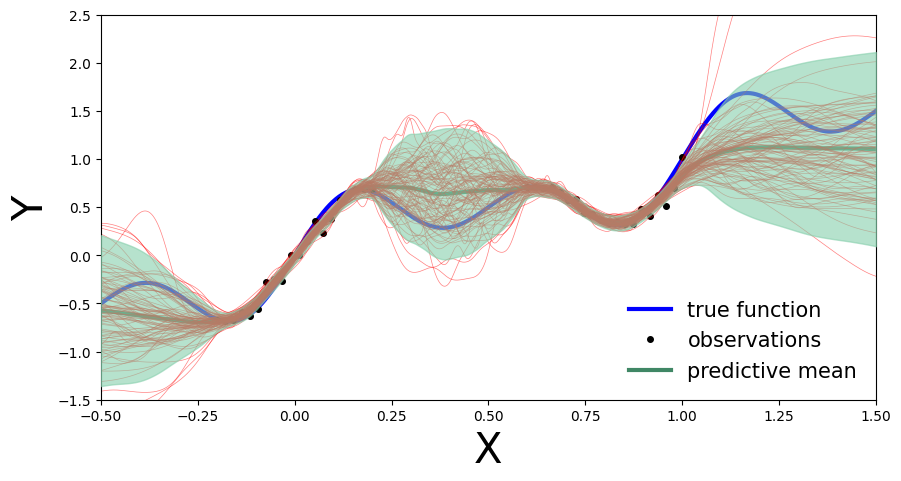

In [9]:
plot_predictions2(svi_samples)

In [10]:
print("Average residual stdev: ", torch.linalg.inv(svi_samples["precision"]).sqrt().mean(dim=[0,1]))
print("Average last layer scale: ", svi_samples["layer2/scale"].mean(dim=[0,1]))

Average residual stdev:  tensor([[0.1646]])
Average last layer scale:  tensor(6.3561)


## Create custom transforms with jacobians

In [ ]:
class MyLowerCholeskyTransform(transforms.LowerCholeskyTransform):
    def log_abs_det_jacobian(self, x, y):
        return super().log_abs_det_jacobian(x, y) # Errors

class MyPositiveDefiniteTransform(transforms.Transform):
    """
    Transform from unconstrained matrices to positive-definite matrices.
    """

    domain = constraints.independent(constraints.real, 2)
    codomain = constraints.positive_definite  # type: ignore[assignment]

    def __eq__(self, other):
        return isinstance(other, MyPositiveDefiniteTransform)

    def _call(self, x):
        x = MyLowerCholeskyTransform()(x)
        return x @ x.mT

    def _inverse(self, y):
        y = torch.linalg.cholesky(y)
        return MyLowerCholeskyTransform().inv(y)
    
    def log_abs_det_jacobian(self, x, y):
        # When implementing, use the method from MyLowerCholeskyTransform
        # then add on for the matrix multiplication. Follow the STAN docs:
        # https://mc-stan.org/docs/reference-manual/transforms.html#covariance-matrices
        return super().log_abs_det_jacobian(x, y) # Errors




In [12]:
@torch.distributions.constraint_registry.biject_to.register(constraints.positive_definite)
@torch.distributions.constraint_registry.biject_to.register(constraints.positive_semidefinite)
def _biject_to_positive_definite(constraint):
    return MyPositiveDefiniteTransform()

## Using HMC

In [14]:
model = TIBNN2.from_data(x_train2, y_train2, width=500, depth=2)
nuts = NUTS(model, jit_compile = True, full_mass = False, init_strategy = pyro.infer.autoguide.init_to_sample)
mcmc = MCMC(nuts, num_samples = 100, warmup_steps = 100, num_chains = 1, mp_context = "spawn")
mcmc.run(x_train2, y_train2)

Warmup:   0%|          | 0/200 [00:00, ?it/s]/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


NotImplementedError: 

## With diagonal normal guide

In [13]:
logging.basicConfig(format='%(message)s', level=logging.INFO)

pyro.set_rng_seed(12)

pyro.clear_param_store()

model = TIBNN2.from_data(x_train2, y_train2, width=500, depth=2)
guide = pyro.infer.autoguide.AutoNormal(model, init_loc_fn=pyro.infer.autoguide.init_to_uniform)

adam = pyro.optim.Adam({"lr": 0.001})
elbo = pyro.infer.Trace_ELBO(num_particles = 1)
svi = pyro.infer.SVI(model, guide, adam, elbo)

losses = do_svi(svi, x_train2, y_train2, check_interval = 500)

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


NotImplementedError: 
                     Trace Shapes:                
                      Param Sites:                
     AutoNormal.locs.layer1/weight 500   1        
   AutoNormal.scales.layer1/weight 500   1        
       AutoNormal.locs.layer1/bias     500        
     AutoNormal.scales.layer1/bias     500        
      AutoNormal.locs.layer1/scale                
    AutoNormal.scales.layer1/scale                
     AutoNormal.locs.layer2/weight 500 500        
   AutoNormal.scales.layer2/weight 500 500        
       AutoNormal.locs.layer2/bias     500        
     AutoNormal.scales.layer2/bias     500        
      AutoNormal.locs.layer2/scale                
    AutoNormal.scales.layer2/scale                
         AutoNormal.locs.precision   1   1        
       AutoNormal.scales.precision   1   1        
  AutoNormal.locs.last/full_matrix   1 501        
AutoNormal.scales.last/full_matrix   1 501        
                     Sample Sites:                
  layer1/

In [ ]:
plt.figure(figsize=(5, 7))
plt.plot(losses)
plt.xlabel("SVI step")
plt.ylabel("ELBO loss");

In [ ]:
svi_predictive = Predictive(model, guide=guide, num_samples=100)
svi_samples = svi_predictive(x_test2)

In [ ]:
plot_predictions2(svi_samples)

In [ ]:
print("Average residual stdev: ", torch.linalg.inv(svi_samples["precision"]).sqrt().mean(dim=[0,1]))
print("Average last layer scale: ", svi_samples["layer2/scale"].mean(dim=[0,1]))